# 课堂练习：基于 orders.txt 的数据统计与可视化分析

**练习要求：**
1. 统计各个门店每个年份的利润总和
2. 绘制 2020 年各个门店利润的条形图，导出为 PNG 图片
3. 绘制各个门店 2014-2020 期间的利润折线图，导出为 PDF 文件（包含单图多折线图与 3×3 子图两种形式）


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体与负号正常显示（兼容 Mac 与 Windows）
plt.rcParams['font.sans-serif'] = ['Hiragino Sans GB', 'Arial Unicode MS', 'SimHei', 'Microsoft YaHei', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False


In [2]:
# 1. 读取 orders.txt 数据集
df = pd.read_csv('orders.txt')
print("数据集大小：", df.shape)
df[['order_id', 'order_date', 'store_name', 'sales', 'profit', 'dt']].head()


数据集大小： (19490, 25)


,order_id,order_date,store_name,sales,profit,dt
0,CN-2014-100007,2014/1/1,定远店,1622.600,291.34,2014
1,CN-2014-100001,2014/1/1,人民店,919.100,144.24,2014
2,CN-2014-100002,2014/1/1,杨店店,284.480,47.53,2014
3,CN-2014-100003,2014/1/1,庐江店,920.976,-41.49,2014
4,CN-2014-100004,2014/1/1,金寨店,95.088,-8.05,2014


## 一、统计各个门店每个年份的利润总和

In [3]:
# 按门店名称 (store_name) 与年份 (dt) 进行分组，计算利润 (profit) 总和
profit_summary = df.groupby(['store_name', 'dt'])['profit'].sum().unstack()

# 按照课件顺序排列各门店
store_order = ['临泉店', '人民店', '众兴店', '定远店', '庐江店', '杨店店', '海恒店', '燎原店', '金寨店']
profit_summary = profit_summary.reindex(store_order)

# 保留两位小数显示
profit_summary.round(2)


dt,2014,2015,2016,2017,2018,2019,2020
store_name,,,,,,,
临泉店,34411.16,30469.80,28155.84,29706.81,33302.40,45279.71,19951.14
人民店,30465.74,26754.56,28559.78,32160.27,28359.82,37983.96,17703.47
众兴店,28154.97,32471.37,36412.47,34681.98,38432.08,41285.12,14090.26
定远店,28806.36,29085.15,32674.93,33676.27,35373.38,35633.18,16953.67
庐江店,27879.87,31117.29,31650.22,33699.87,38666.46,35320.21,15994.17
杨店店,27695.31,25952.14,33515.07,31803.43,33187.21,37005.88,12470.98
海恒店,27445.98,30868.76,30902.04,30008.16,29147.29,38743.12,15510.21
燎原店,25737.45,29066.12,26743.07,28778.87,32751.69,36804.66,13759.53
金寨店,31643.05,30137.84,22644.52,26687.14,32583.92,38375.27,16678.98


## 二、绘制 2020 年各个门店利润的条形图（导出为 PNG）

已成功导出为 2020年各个门店利润条形图.png


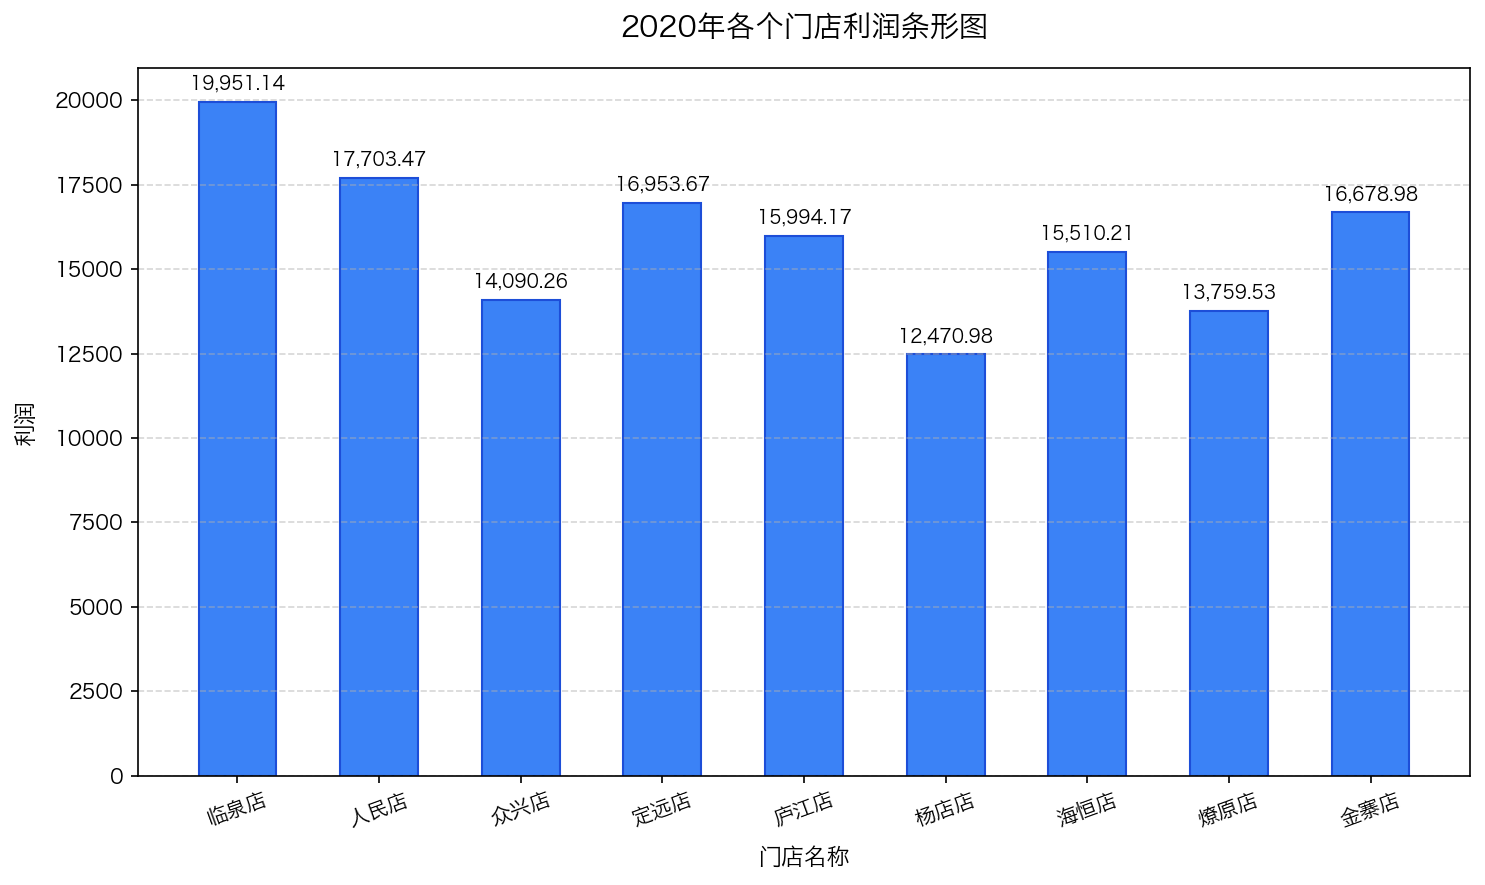

In [4]:
# 提取 2020 年各个门店的利润
profit_2020 = profit_summary[2020]

plt.figure(figsize=(10, 6), dpi=150)
bars = plt.bar(profit_2020.index, profit_2020.values, color='#3b82f6', edgecolor='#1d4ed8', width=0.55)

plt.title('2020年各个门店利润条形图', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('门店名称', fontsize=11, labelpad=8)
plt.ylabel('利润', fontsize=11, labelpad=8)
plt.xticks(rotation=20, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 在每个柱子上方添加具体的数值标签
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height + 250,
             f'{height:,.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()

# 导出为 png 图片（注意在 plt.show() 之前调用）
plt.savefig('2020年各个门店利润条形图.png', format='png', bbox_inches='tight', dpi=300)
print("已成功导出为 2020年各个门店利润条形图.png")
plt.show()


## 三、绘制各个门店 2014-2020 期间的利润折线图（导出为 PDF）

课件中展示了两种绘制方案：
- **方案 A（多折线汇合图）**：所有门店在同一张图内对比展示，附带完整图例说明。
- **方案 B（3×3 子图矩阵）**：每家门店独立为一个子图，适合观察单店独立走势。

下面分别绘制并导出为 PDF 文件。


已成功导出为 2014-2020各门店利润折线图.pdf


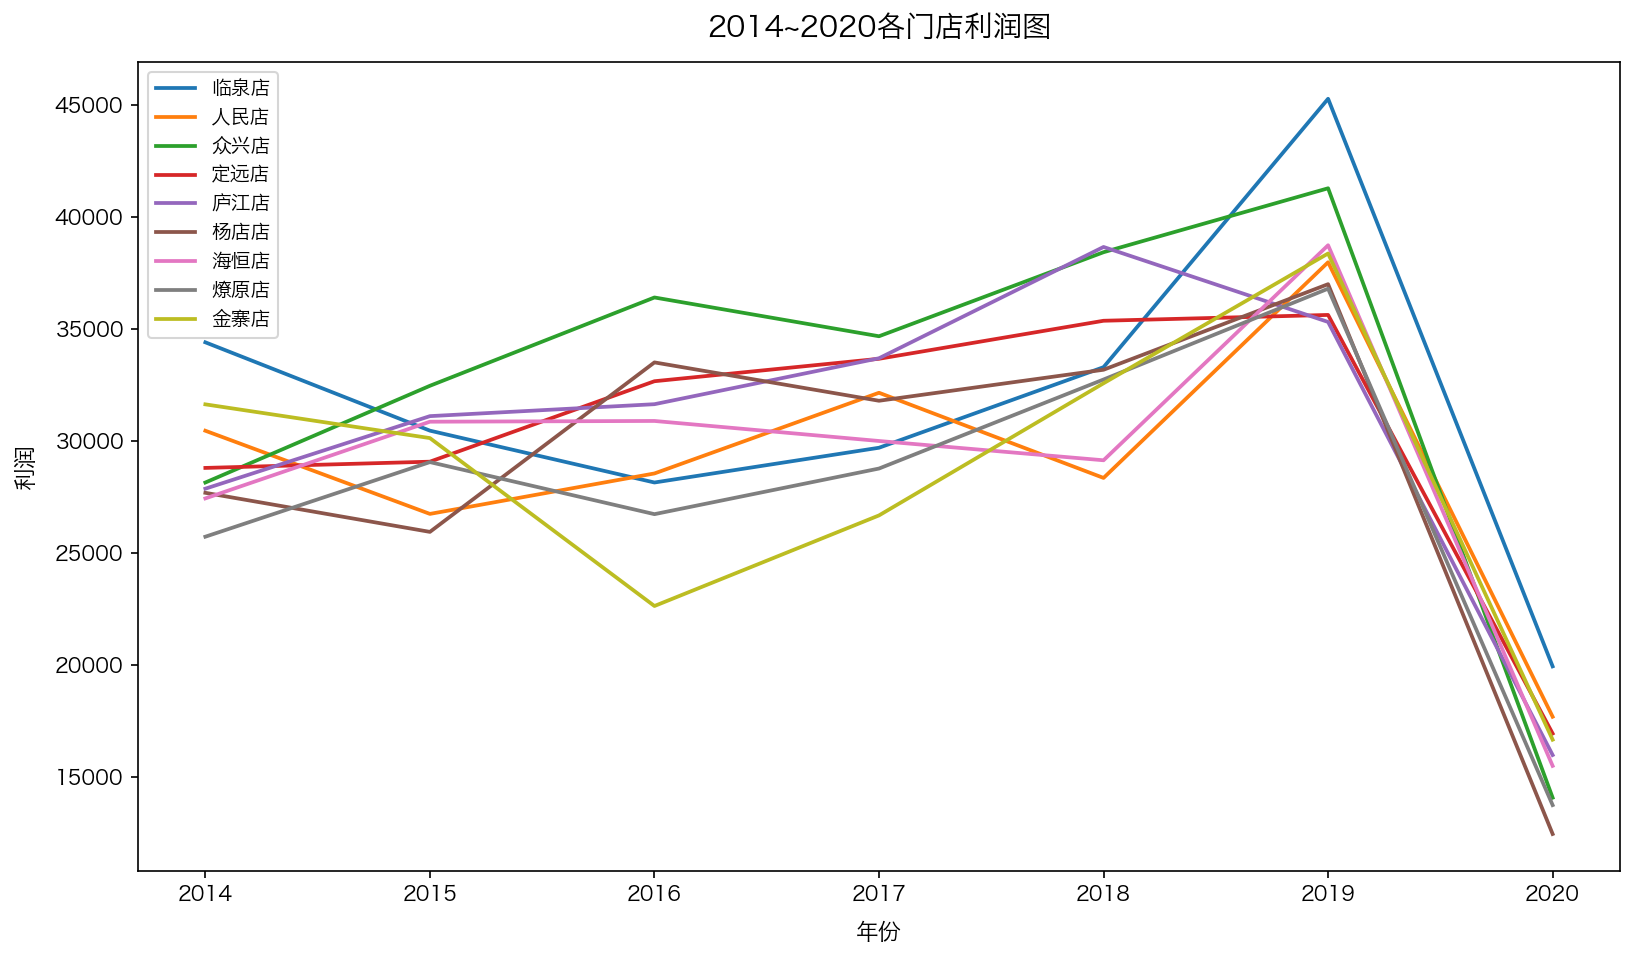

In [5]:
# 方案 A：单图多折线图（对应课件右图）
years = profit_summary.columns

plt.figure(figsize=(11, 6.5), dpi=150)
for store in profit_summary.index:
    plt.plot(years, profit_summary.loc[store], label=store, linewidth=1.8)

plt.title('2014~2020各门店利润图', fontsize=14, pad=12)
plt.xlabel('年份', fontsize=11, labelpad=8)
plt.ylabel('利润', fontsize=11, labelpad=8)
plt.xticks(years, fontsize=10)
plt.yticks(fontsize=10)
plt.legend(loc='upper left', frameon=True, fontsize=9.5)
plt.tight_layout()

# 导出为 PDF 文件
plt.savefig('2014-2020各门店利润折线图.pdf', format='pdf', bbox_inches='tight')
print("已成功导出为 2014-2020各门店利润折线图.pdf")
plt.show()


已成功导出为 2014-2020各门店利润图_子图.pdf


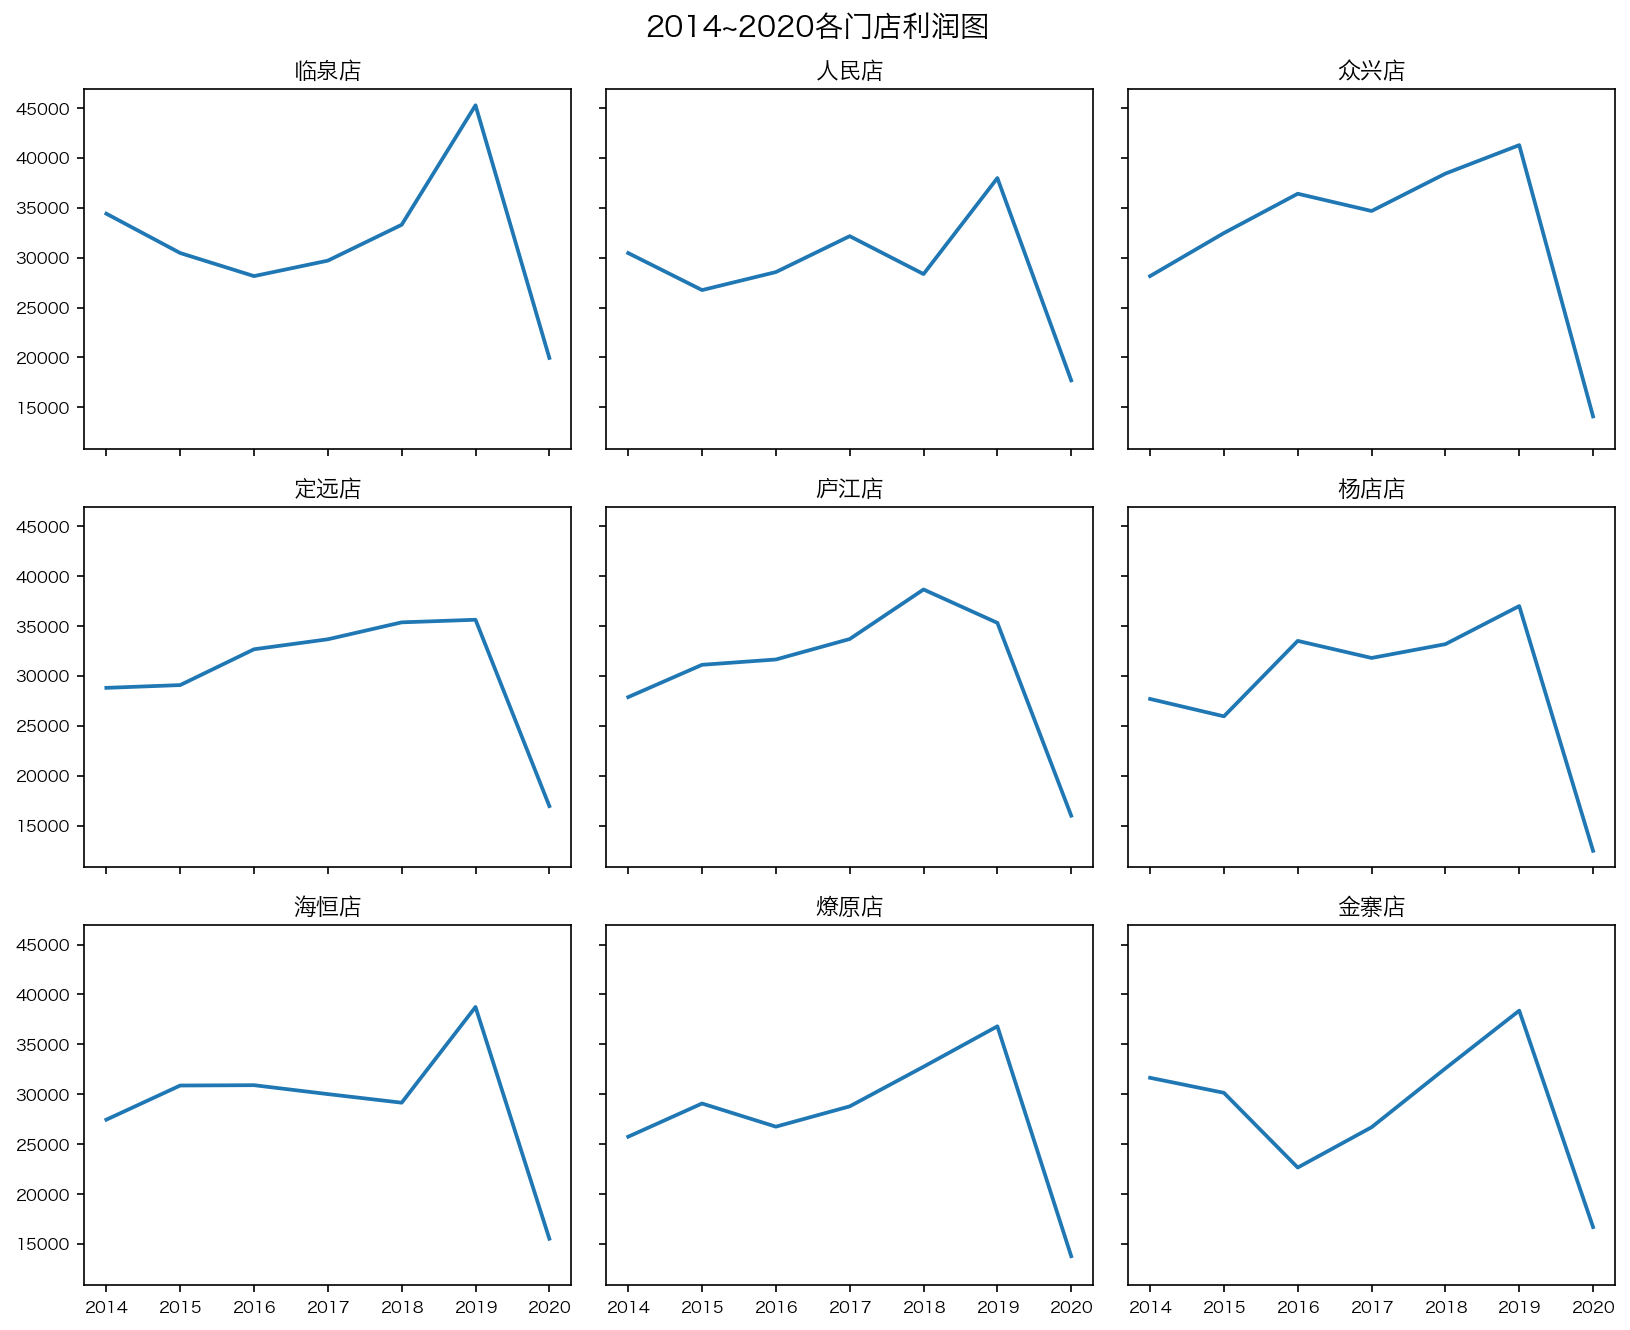

In [6]:
# 方案 B：3x3 子图（对应课件左图）
fig, axes = plt.subplots(3, 3, figsize=(11, 9), sharex=True, sharey=True, dpi=150)
axes = axes.flatten()

for i, store in enumerate(store_order):
    ax = axes[i]
    ax.plot(years, profit_summary.loc[store], linewidth=1.8, color='#1f77b4')
    ax.set_title(store, fontsize=11, pad=5)
    ax.tick_params(labelsize=8)
    if i >= 6:
        ax.set_xticks(years)
        ax.set_xticklabels(years, fontsize=8)

fig.suptitle('2014~2020各门店利润图', fontsize=14, y=0.98)
plt.tight_layout()

# 导出为 PDF 文件
plt.savefig('2014-2020各门店利润图_子图.pdf', format='pdf', bbox_inches='tight')
print("已成功导出为 2014-2020各门店利润图_子图.pdf")
plt.show()
